# TP1 : Algorithme EM et modèle de mélange gaussien

## G3 SDI - Introduction à l'Estimation Statistique

L'objectif de ce TP est d'implémenter l'algorithme EM pour estimer par maximum de vraisemblance les paramètres d'un modèle de mélange gaussien.

On utilisera le dataset *Old Faithful*, qui décrit 272 éruptions du geyser appelé Old Faithful du parc national de Yellowstone aux États-Unis. Chaque observation est constituée de 2 variables : la durée de l'éruption (en minutes) et le temps d'attente avant l'éruption (en minutes).

### Instructions

1. Renommez votre notebook sous la forme `tp1_Nom1_Nom2.ipynb`. 

2. Votre code et les résultats obtenus doivent être commentés !

3. Déposez votre notebook sur Moodle dans la section prévue à cet effet avant la date limite.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Compte-rendu écrit par FERNANDES--STRAG Henry, TORRES--Leguet Alexandre, 9/10/26.
</div>

In [1]:
# Import necessary libraries
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import scipy.stats as ss

**Q1**. Charger le dataset, normaliser puis visualiser les données. Commenter.

Matrice de corrélation:
[[1.         0.90081117]
 [0.90081117 1.        ]]


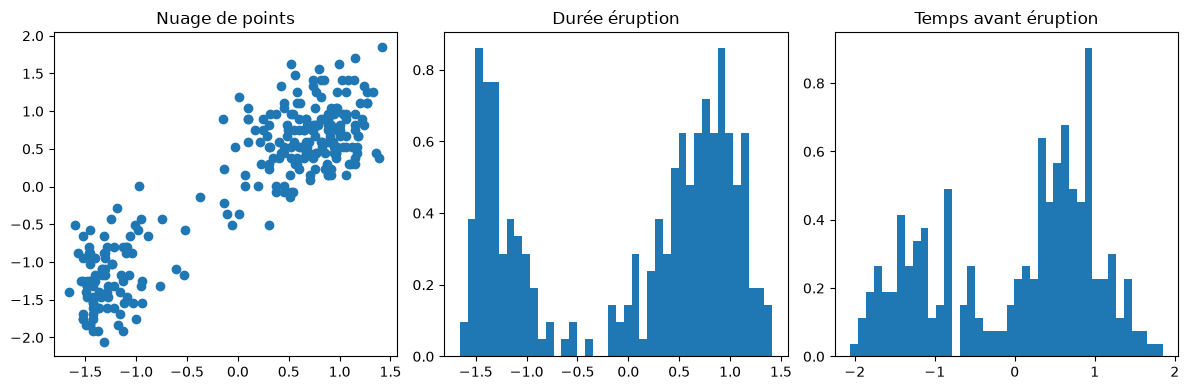

In [2]:
# Load the "Old Faithful" dataset from the archive

dataset = np.load("oldfaithful.npy")

# Standardize data to avoid numerical instabilities

X = (dataset - np.mean(dataset, axis=0)) / np.std(dataset, axis=0)

print("Matrice de corrélation:")
print(np.corrcoef(X.T))

# Display data

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].scatter(X[:, 0], X[:, 1])
axes[0].set_title('Nuage de points')

axes[1].hist(X[:, 0], bins=40, density=True)
axes[1].set_title('Durée éruption')

axes[2].hist(X[:, 1], bins=40, density=True)
axes[2].set_title('Temps avant éruption')

plt.tight_layout()
plt.show()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
L'affichage des points nous montre que les données semblent se répartir en deux groupes distincts. Ces deux groupes suivent chacun une loi distincte (la loi jointe est bimodale), donc il semble judicieux d'utiliser un modèle de mélange gaussien pour modéliser ces 2 lois.
</div>

**Q2**. On note $\mathbf{x}_1,...,\mathbf{x}_n$ les données. On souhaite les modéliser par un modèle de mélange gaussien à $K$ composantes.

Écrire une fonction permettant de calculer la log-vraisemblance :
$$ \log \mathcal{L}(\theta;\mathbf{x}_1,...,\mathbf{x}_n) = \sum_{i=1}^n \log \left( \sum_{k=1}^K \pi_k \frac{1}{2 \pi \text{det}(\boldsymbol{\Sigma}_k)^{1/2}} \exp \left( \frac{1}{2} (\mathbf{x}_i - \boldsymbol{\mu}_k)^{\top} \boldsymbol{\Sigma}_k^{-1} (\mathbf{x}_i - \boldsymbol{\mu}_k) \right) \right), $$
avec $\theta = \{ \boldsymbol{\mu_1}, ..., \boldsymbol{\mu_K}, \boldsymbol{\Sigma}_1, ..., \boldsymbol{\Sigma}_K, \pi_1, ..., \pi_K \}$.

On pourra utiliser la fonction `multivariate_normal.pdf` de la librairie scipy.stats.

In [3]:
def log_likelihood(X, mu, cov, p):
    # X is the data, array of size N x 2
    # mu stores all the mu parameters, array of size K x 2
    # cov stores all the Sigma parameters, array of size K x 2 x 2
    # p stores all the pi parameters, array of size K

    K = len(p)

    """
    # première version, écrite avec une boucle sur les données
    logL = 0
        for i in range(X.shape[0]):
            L = 0
            for k in range(K):
                y = ss.multivariate_normal.pdf(X[i], mean=mu[k], cov=cov[k])
                L += p[k] * y
            logL += np.log(L)
        return logL
    """

    # version vectorisée, on donne à pdf X tout entier et il nous renvoit un tableau de taille N
    L = np.zeros(X.shape[0])
    for k in range(K):
        L += p[k] * ss.multivariate_normal.pdf(X, mean=mu[k], cov=cov[k])
    logL = np.log(L)
    return np.sum(logL)

In [4]:
# test de la fonction

K = 2
mu = np.array([[0, 0], [1, 1]])
cov = np.array([[[1, 0], [0, 1]], [[1, 0], [0, 1]]])
p = np.array([0.4, 0.6])

print("log-vraisemblance:")
print(log_likelihood(X, mu, cov, p))

print("log-vraisemblance moyenne:")
print(log_likelihood(X, mu, cov, p) / X.shape[0])

log-vraisemblance:
-805.2227471944294
log-vraisemblance moyenne:
-2.9603777470383434


In [5]:
K = 2
mu = np.array([[10, 10], [5, 5]])
cov = np.array([[[1, 0], [0, 1]], [[1, 0], [0, 1]]])
p = np.array([0.4, 0.6])

print("log-vraisemblance:")
print(log_likelihood(X, mu, cov, p))

log-vraisemblance:
-7710.847131727691


<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
La fonction semble bien fonctionner. On teste avec des valeurs prises à la main, et on voit déjà la cohérence des résultats :

- pour une loi normale multivariée avec des moyennes très éloignées des données, on obtient une log-vraisemblance bien plus petite (-7710) qu'avec des moyennes du même ordre de grandeur que les données (-805).
- si jamais $X$ suit une loi normale centrée réduite, alors $\text{log}\mathcal{L}(0, I; x) = - \text{log}(2\pi) - \frac{1}{2} ||x||^2$, d'espérance $$- \text{log}(2\pi) - \frac{1}{2} 2 = -2.84$$
car $E[X^2] = 2$. Notre première valeur de -2.96 a donc le bon ordre de grandeur.
</div>

**Q3**. Écrire une fonction qui implémente l'algorithme EM dans ce modèle, prenant pour arguments les données, le nombre de composantes $K$, et le nombre d'itérations de l'algorithme $N_{\text{iter}}$. Cette fonction retournera un tableau de taille $N_{\text{iter}} + 1$ contenant l'évolution des valeurs de la log-vraisemblance, ainsi que les valeurs finales des paramètres.

Initialisation des paramètres :
- Pour les moyennes, les $K$ premières observations du dataset ;
- Pour les matrices de covariances, la matrice identité ;
- $\pi_k = 1/K$ pour tout $k$.

In [6]:
def EM_algorithm_v1(X, K, Niter):
    # Initialize parameters

    # X : (N, D), dans l'exemple D=2

    N = X.shape[0]
    D = X.shape[1]

    lls = []

    mu = X[0:K].copy() # (K, D) on prend les K premieres observations, en faisant une copie pour ne pas modifier X quand on modifira mu 
    cov = np.array([np.eye(D)] * K) # (K, D, D) np.eye(D) = I_D
    p = np.ones(K) / K

    for i in range(0, Niter):
        # E-STEP
        ll = log_likelihood(X, mu, cov, p) # calcul de la log-vraisemblance pour les paramètres actuels (seulement pour le suivi de la convergence)
        lls.append(ll)

        # matrices des r_ik courants, cf cours
        # r_ik = p_k * p(x_i | mu_k, cov_k) / (somme_k' p_k' * N(x_i | mu_k', cov_k'))
        r = np.zeros((N, K))
        for k in range(K):
            r[:, k] = p[k] * ss.multivariate_normal.pdf(X, mean=mu[k], cov=cov[k])
            # on calcule tous les r_ik pour un k donné à la fois, en vectorisant sur i
            # mais on garde une boucle sur k
        r /= np.sum(r, axis=1, keepdims=True)
        
        # M-STEP

        # mu
        for k in range(K):
            # on veut mu[k] = (somme_i r[i,k] * xi) / (somme_i r[i,k])
            # le dénominateur ne pose pas de problème
            # pour le numérateur, il faut multiplier chaque xi de taille (D,) par r[i,k] un scalaire : il y a broadcasting
            # on utilise pour cela r[:, [k]] pour obtenir un tableau (N, 1)
            # puis (N, 1) * (N, D) = (N, D) par broadcast
            mu[k] = np.sum(r[:, [k]] * X, axis=0) / np.sum(r[:, k])

        # on peut aussi vectoriser la boucle, mais c'est moins clair:
        #Nk = np.sum(r, axis=0) # (K,)
        #mu = (r.T @ X) / Nk[:, None] # r.T @ X = (K, N) @ (N, D) = (K, D), puis on divise chaque ligne par Nk[k]

        # cov
        for k in range(K):
            # on veut cov[k] = (somme_i r[i,k] * (xi - mu[k]) (xi - mu[k])^T) / (somme_i r[i,k])
            # le dénominateur ne pose pas de problème (cf précédemment)
            # pour le numérateur, on calcul d'abord (xi - mu[k]) (xi - mu[k])^T) :
            d = X - mu[k] # (N, D)
            dd = d[:, :, None] * d[:, None, :] # (N, D, 1) * (N, 1, D) = (N, D, D), c'est l'outer product (X-mu)(X-mu)^T batché sur toutes les données

            # puis on utilise le broadcast pour multiplier chaque (D, D) par r[i,k] un scalaire
            # donc on utilise r[:, k, None, None] pour obtenir un tableau (N, 1, 1), qu'on multiplie par (N, D, D) pour obtenir (N, D, D)
            # puis on somme sur les exemples (axis=0)
            cov[k] = np.sum(r[:, k, None, None] * dd, axis=0) / np.sum(r[:, k])
            cov[k] += 1e-6 * np.eye(D) # on a des fois des problèmes numériques (covariance non définie positive), on ajoute un petit terme pour régulariser

        # pi
        for k in range(K):
            p[k] = np.sum(r[:, k]) / N

    lls.append(log_likelihood(X, mu, cov, p)) # log-vraisemblance finale

    return mu, cov, p, lls

In [7]:
mu, cov, p, lls = EM_algorithm_v1(X, K=2, Niter=100)

print("mu:")
print(mu)
print("cov:")
print(cov)
print("p:", p)
print("log-likelihood:", lls[-1])

mu:
[[ 0.70385258  0.66846605]
 [-1.27396752 -1.20991818]]
cov:
[[[0.13095348 0.06084191]
  [0.06084191 0.19575122]]

 [[0.05329147 0.02814828]
  [0.02814828 0.18299541]]]
p: [0.6441271 0.3558729]
log-likelihood: -385.46069564730124


**Q4**. Faire tourner l'algorithme avec $K = 2$ et $N_{\text{iter}} = 50$.

Afficher l'évolution de la log-vraisemblance en fonction des itérations. Commenter.

Sur une même figure, afficher le dataset et représenter les estimations des deux lois normales du mélange à l'aide d'un *contour plot*. On pourra utiliser la fonction `plt.contour` (voir par exemple [ici](https://gist.github.com/gwgundersen/90dfa64ca29aa8c3833dbc6b03de44be)).

Text(0, 0.5, 'Log-vraisemblance')

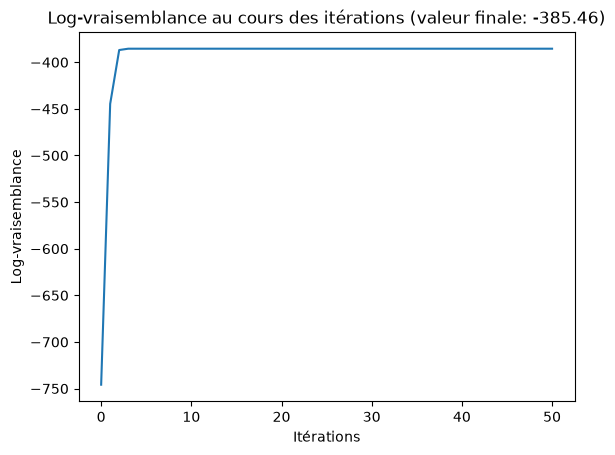

In [8]:
K = 2
Niter = 50

mu, cov, p, lls = EM_algorithm_v1(X, K, Niter)

plt.plot(lls)
plt.title(f"Log-vraisemblance au cours des itérations (valeur finale: {lls[-1]:.2f})")
plt.xlabel("Itérations")
plt.ylabel("Log-vraisemblance")

Text(0, 0.5, "temps d'attente")

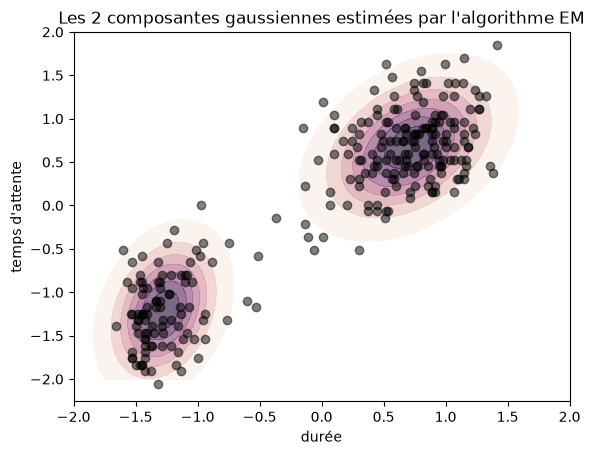

In [9]:
cmap = sns.cubehelix_palette(start=6, light=1, as_cmap=True) # palette de couleurs seaborn

# code inspiré de https://gist.github.com/gwgundersen/90dfa64ca29aa8c3833dbc6b03de44be
xx, yy = np.meshgrid(np.linspace(-2, 2, 200), np.linspace(-2, 2, 200))
grille = np.dstack((xx, yy))

for k in range(K):
    z = ss.multivariate_normal(mean=mu[k], cov=cov[k]).pdf(grille)
    niveaux = np.linspace(0.05 * z.max(), z.max(), 8)
    plt.contourf(xx, yy, z, levels=niveaux, cmap=cmap, alpha=0.7)
    # on utilise contourf avec des niveaux (espacés de 5% du max jusqu'au max), repris d'un TP Python précédent

plt.scatter(x=X[:, 0], y=X[:, 1], color='black', alpha=0.5) # on affiche les données

plt.title("Les 2 composantes gaussiennes estimées par l'algorithme EM")
plt.xlabel("durée")
plt.ylabel("temps d'attente")

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
On observe que l'algorithme converge très rapidement (quelques itérations), et que les itérés successifs ont bien une log-vraisemblance de plus en plus grande.

On visualise les données par-dessus les 2 gaussiennes, et on comprend que ce sont ces 2 gaussiennes qui permettent en effet de maximiser la vraisemblance des données. C'est-à-dire que si on prenait d'autres gaussiennes, la vraisemblance des données serait plus faible. Cela correspond au fait que l'algorithme EM a convergé.

Toutefois, cela n'assure pas qu'une autre modélisation (qui utilise par exemple davantage de gaussiennes ou bien d'autres lois) ne donneraient pas une meilleure vraisemblance (bien qu'intuitivement et visuellement, on imagine bien que 2 gaussiennes suffisent).
</div>

**Q5**. On souhaite maintenant étudier l'influence de l'initialisation sur les résultats. Modifier la fonction implémentant l'algorithme EM en y rajoutant un argument pour la graine aléatoire. Les paramètres seront maintenant initialisés de la manière suivante :
- $\boldsymbol{\mu}_k \sim \mathcal{N}(\mathbf{0},\mathbf{I}_2)$ ;
- $[\pi_1, ..., \pi_K]^{\top} \sim \text{Dirichlet}([1, ..., 1]^{\top})$ ;
- On gardera l'initialisation des matrices de covariance à la matrice identité.

In [10]:
def EM_algorithm_v2(X, K, Niter, seed):
    # Initialize parameters

    rng = np.random.default_rng(seed)

    N = X.shape[0]
    D = X.shape[1]

    lls = []

    mu = rng.normal(size=(K, D))
    cov = np.array([np.eye(D)] * K) # comme dans la v1
    p = rng.dirichlet(np.ones(K))

    # le reste ne change pas

    for i in range(0, Niter):
            # E-STEP
            ll = log_likelihood(X, mu, cov, p) # calcul de la log-vraisemblance pour les paramètres actuels (seulement pour le suivi de la convergence)
            lls.append(ll)
    
            # matrices des r_ik courants, cf cours
            # r_ik = p_k * p(x_i | mu_k, cov_k) / (somme_k' p_k' * N(x_i | mu_k', cov_k'))
            r = np.zeros((N, K))
            for k in range(K):
                r[:, k] = p[k] * ss.multivariate_normal.pdf(X, mean=mu[k], cov=cov[k])
                # on calcule tous les r_ik pour un k donné à la fois, en vectorisant sur i
                # mais on garde une boucle sur k
            r /= np.sum(r, axis=1, keepdims=True)
            
            # M-STEP
    
            # mu
            for k in range(K):
                # on veut mu[k] = (somme_i r[i,k] * xi) / (somme_i r[i,k])
                # le dénominateur ne pose pas de problème
                # pour le numérateur, il faut multiplier chaque xi de taille (D,) par r[i,k] un scalaire : il y a broadcasting
                # on utilise pour cela r[:, [k]] pour obtenir un tableau (N, 1)
                # puis (N, 1) * (N, D) = (N, D) par broadcast
                mu[k] = np.sum(r[:, [k]] * X, axis=0) / np.sum(r[:, k])
    
            # on peut aussi vectoriser la boucle, mais c'est moins clair:
            #Nk = np.sum(r, axis=0) # (K,)
            #mu = (r.T @ X) / Nk[:, None] # r.T @ X = (K, N) @ (N, D) = (K, D), puis on divise chaque ligne par Nk[k]
    
            # cov
            for k in range(K):
                # on veut cov[k] = (somme_i r[i,k] * (xi - mu[k]) (xi - mu[k])^T) / (somme_i r[i,k])
                # le dénominateur ne pose pas de problème (cf précédemment)
                # pour le numérateur, on calcul d'abord (xi - mu[k]) (xi - mu[k])^T) :
                d = X - mu[k] # (N, D)
                dd = d[:, :, None] * d[:, None, :] # (N, D, 1) * (N, 1, D) = (N, D, D), c'est l'outer product (X-mu)(X-mu)^T batché sur toutes les données
    
                # puis on utilise le broadcast pour multiplier chaque (D, D) par r[i,k] un scalaire
                # donc on utilise r[:, k, None, None] pour obtenir un tableau (N, 1, 1), qu'on multiplie par (N, D, D) pour obtenir (N, D, D)
                # puis on somme sur les exemples (axis=0)
                cov[k] = np.sum(r[:, k, None, None] * dd, axis=0) / np.sum(r[:, k])
                cov[k] += 1e-6 * np.eye(D) # on a des fois des problèmes numériques (covariance non définie positive), on ajoute un petit terme pour régulariser
    
            # pi
            for k in range(K):
                p[k] = np.sum(r[:, k]) / N

    lls.append(log_likelihood(X, mu, cov, p)) # log-vraisemblance finale

    return mu, cov, p, lls

seed 0 : ll = -385.46069564730124
seed 1 : ll = -385.46069564730124
seed 2 : ll = -385.46069564730124
seed 3 : ll = -385.46069564730124
seed 4 : ll = -385.46069564730124


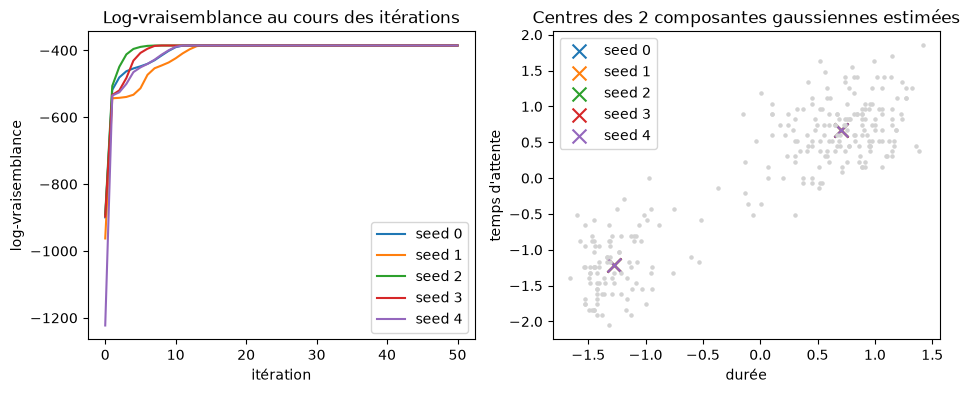

In [23]:
K = 2
Niter = 50
seeds = [123456789, 987654321, 42, 314159265, 271828182]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for i, seed in enumerate(seeds):
    mu, cov, p, lls = EM_algorithm_v2(X, K, Niter, seed)
    print(f"seed {i} : ll = {lls[-1]}")

    ax[0].plot(lls, label=f"seed {i}")
    ax[1].scatter(mu[:, 0], mu[:, 1], marker="x", s=100, color=f"C{i}", label=f"seed {i}")

ax[1].scatter(X[:, 0], X[:, 1], s=5, c="lightgray")
ax[0].set(xlabel="itération", ylabel="log-vraisemblance")
ax[0].legend()
ax[1].legend()
ax[0].set_title("Log-vraisemblance au cours des itérations")
ax[1].set_title("Centres des 2 composantes gaussiennes estimées")
ax[1].set_xlabel("durée")
ax[1].set_ylabel("temps d'attente")
plt.show()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
La vitesse de convergence dépend fortement de l'initialisation, même pour ce problème simple. Il faut dans certains cas presque 20 itérations pour converger, alors que dans d'autres moins de 5 suffisent. Dans tous les cas, on converge vers la valeur de -385 de log-vraisemblance, et la solution trouvée est la même.
</div>

**Q6**. On choisit maintenant $K=3$. Représenter l'évolution de la log-vraisemblance pour 10 graines aléatoires différentes. Commenter.

Afficher deux cas où la solution retournée par l'algorithme EM est visuellement différente. Commenter.

Quelle estimation de paramètres doit-on choisir ?

seed 0 : ll = -376.12663964412894
seed 1 : ll = -374.41085018651324
seed 2 : ll = -383.8406994053058
seed 3 : ll = -374.41521228223013
seed 4 : ll = -376.1279119639933
seed 5 : ll = -374.4736122182295
seed 6 : ll = -374.4190235023906
seed 7 : ll = -374.52470762724647
seed 8 : ll = -374.419216334713
seed 9 : ll = -374.41073992188745


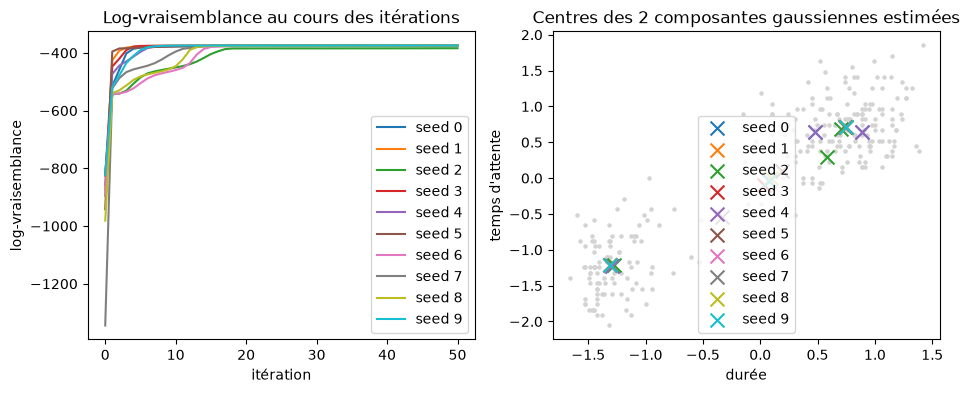

In [24]:
K = 3
Niter = 50
seeds = list(range(1, 11))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[1].scatter(X[:, 0], X[:, 1], s=5, c="lightgray")

for i, seed in enumerate(seeds):
    mu, cov, p, lls = EM_algorithm_v2(X, K, Niter, seed)
    print(f"seed {i} : ll = {lls[-1]}")

    ax[0].plot(lls, label=f"seed {i}")
    ax[1].scatter(mu[:, 0], mu[:, 1], marker="x", s=100, color=f"C{i}", label=f"seed {i}")

ax[0].set(xlabel="itération", ylabel="log-vraisemblance")
ax[0].legend()
ax[1].legend()
ax[0].set_title("Log-vraisemblance au cours des itérations")
ax[1].set_title("Centres des 2 composantes gaussiennes estimées")
ax[1].set_xlabel("durée")
ax[1].set_ylabel("temps d'attente")
plt.show()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Avec K=3, l'algorithme EM converge également (en moyenne un peu plus lentement que K=2). La valeur de log-vraisemblance cette fois diffère entre les seeds, et elle est en générale meilleure qu'avec K=2 (-374 contre -385 pour K=2).
On observe également que les solutions trouvées diffèrent entre elles (contrairement au cas K=2). Cela montre que l'estimateur par maximum de vraisemblance avec un modèle de mélange gaussien avec K=3 possède une variance plus élevée que celui en K=2 (qui semble avoir une variance nulle).

Entre les différents résultats trouvés, on choisit alors l'estimation qui a la plus grande vraisemblance.
</div>

**Q7**. On cherche maintenant à choisir la valeur optimale de $K$. Pour cela, on aimerait pouvoir comparer la vraisemblance des modèles obtenus avec différentes valeurs de $K$.

Cela peut se faire au travers d'un critère de sélection de modèle. Dans ce TP, nous étudierons le critère dit BIC :
$$ \text{BIC}(m) = k(m) \log(n) - 2 \log \mathcal{L}(m),$$
où $m$ est un modèle (ici donné par une valeur de $K$), $k(m)$ est le nombre de paramètres libres dans le modèle, $n$ le nombre d'échantillons, et $\mathcal{L}(m)$ le maximum de la fonction de vraisemblance de le modèle $m$. On sélectionne le modèle avec le plus faible BIC.

Montrer que $$k(m) = \frac{K}{2} (D+1)(D+2) - 1.$$

Comparer les valeurs de $K$ allant de 1 à 6. Quel est le modèle optimal d'après le critère BIC ?

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On calcule le nombre de paramètres du modèle de mélange gaussien à $K$ composantes, où chaque gaussienne est de dimension $D$.
Une composante est définie par un vecteur moyenne $\mu_k$ de taille $D$ et une matrice de covariance $\Sigma_k$ de taille $(D,D)$.
Toutefois, cette matrice doit être symétrique donc le nombre de paramètres libres qui s'y trouvent est $\frac{D(D+1)}{2}$.

La composante $k$ apporte donc $\frac{1}{2}D(D+1) + D$ paramètres libres.

Il faut ensuite rajouter 1 paramètre par composante ($\pi_k$), seulement tous les $\pi_k$ ne sont pas libres car leur somme doit valoir 1, il y en a donc $K-1$ qui sont libres.

Au total, le mélange comporte :

$$
\begin{aligned}
k(m) &= K \Big(\frac{1}{2} D(D+1) + D\Big) + K - 1 \\
&= \frac{K}{2}D^2 + \frac{K}{2}D + KD + K - 1 \\
&= \frac{K}{2} (D^2 + 3D + 2) -1 \\
&= \frac{K}{2} (D+1)(D+2) -1 \\
\end{aligned}
$$

</div>

In [13]:
def BIC(K, n, D, ll):
    k_m = K/2 * (D+1) * (D+2) - 1
    return k_m * np.log(n) - 2 * ll

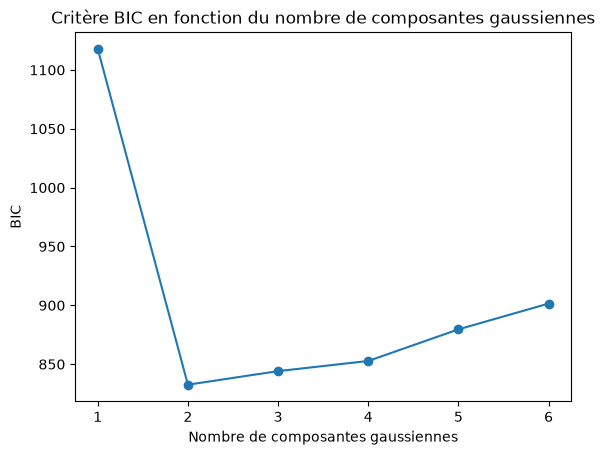

In [14]:
Ks = np.arange(1, 7)

Niter = 50
seeds = list(range(1, 11))

BICs = []

for K in Ks:
    ll_max = -np.inf

    for i, seed in enumerate(seeds):
        mu, cov, p, lls = EM_algorithm_v2(X, K, Niter, seed)

        if lls[-1] > ll_max:
            ll_max = lls[-1]

    BICs.append(BIC(K, X.shape[0], X.shape[1], ll_max))    

plt.plot(Ks, BICs, marker='o')
plt.title("Critère BIC en fonction du nombre de composantes gaussiennes")
plt.xlabel("Nombre de composantes gaussiennes")
plt.ylabel("BIC")
plt.show()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

La valeur de K qui minimise le BIC est bien $K=2$, ce qui semble cohérent avec la visualisation qu'on a fait des données en question 1.
Minimiser le BIC revient à trouver un compromis entre la fidélité aux données (via la log-vraisemblance, qui grossit avec K) et l'expressivité du modèle (via le nombre de paramètres libres et le nombre d'échantillons). Cela revient à trouver le modèle dont l'expressivité donne le meilleur compromis.

</div>

**Question bonus**. Expliquer comment le modèle de mélange gaussien peut être utilisé pour du clustering.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Le but du clustering est d'identifier des clusters dans les données, c'est-à-dire trouver des regroupements de données, puis une fois ces clusters trouvés, affecter un point à un des clusters.

Pour identifier les clusters, on peut modéliser les données comme suivant un modèle de mélange, dont il nous faut optimiser les paramètres. On peut ainsi, comme précédemment, utiliser l'algorithme EM pour trouver le modèle de mélange gaussien qui explique le mieux les données (c'est-à-dire qui maximise leur vraisemblance). On peut également utiliser le critère BIC pour trouver le nombre de clusters optimal.

Ensuite, une fois les clusters trouvés, pour affecter un point donné à un cluster, on calcule la probabilité a posteriori $P(z_i=k | x_i, \theta)$ puis on affecte à $x_i$ le $k$ qui maximise cette probabilité. (on peut aussi en déduire un degré de confiance entre les différents clusters en plus de prendre l'argmax).
</div>

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On applique cette méthode sur le dataset penguins de seaborn, qui regroupe les données d'une population de 333 pingouins. La population comprend 3 espèces de pingouins (variable latente) que nous allons essayer de clusteriser grâce à l'observation seule de la longueur et la hauteur du bec.
</div>

In [15]:
dataset = sns.load_dataset('penguins', cache=False)
dataset = dataset.dropna()

Text(0.5, 1.0, 'Longueur et hauteur du bec des pingouins')

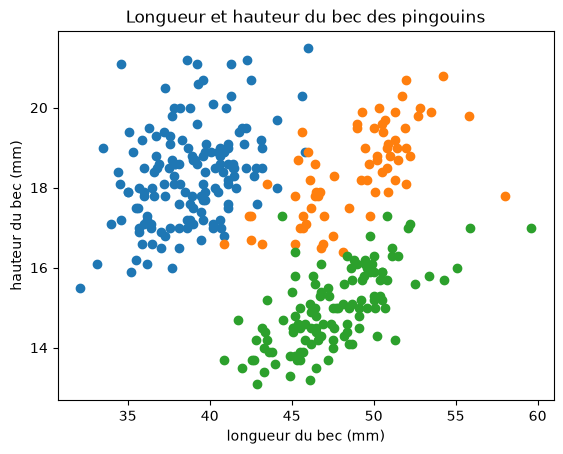

In [16]:
pingouins_adelie = dataset[dataset['species'] == "Adelie"]
pingouins_chinstrap = dataset[dataset['species'] == "Chinstrap"]
pingouins_gentoo = dataset[dataset['species'] == "Gentoo"]

plt.scatter(pingouins_adelie['bill_length_mm'], pingouins_adelie['bill_depth_mm'])
plt.scatter(pingouins_chinstrap['bill_length_mm'], pingouins_chinstrap['bill_depth_mm'])
plt.scatter(pingouins_gentoo['bill_length_mm'], pingouins_gentoo['bill_depth_mm'])

plt.xlabel("longueur du bec (mm)")
plt.ylabel("hauteur du bec (mm)")
plt.title("Longueur et hauteur du bec des pingouins")

In [17]:
X_peng = dataset[['bill_length_mm', 'bill_depth_mm']].to_numpy()
X_peng = (X_peng - np.mean(X_peng, axis=0)) / np.std(X_peng, axis=0)

print(X_peng.shape)

(333, 2)


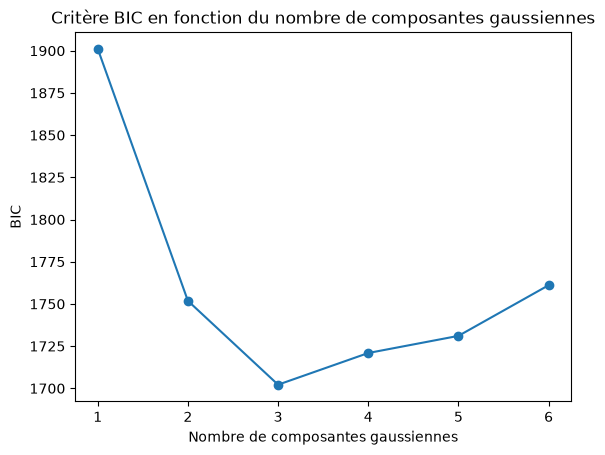

In [25]:
# même code que pour Q7, on utilise le critère BIC pour choisir le nombre de composantes gaussiennes

Ks = np.arange(1, 7)

Niter = 50
seeds = list(range(1, 11))

BICs = []

for K in Ks:
    ll_max = -np.inf

    for i, seed in enumerate(seeds):
        mu, cov, p, lls = EM_algorithm_v2(X_peng, K, Niter, seed)

        if lls[-1] > ll_max:
            ll_max = lls[-1]

    BICs.append(BIC(K, X_peng.shape[0], X_peng.shape[1], ll_max))

plt.plot(Ks, BICs, marker='o')
plt.title("Critère BIC en fonction du nombre de composantes gaussiennes")
plt.xlabel("Nombre de composantes gaussiennes")
plt.ylabel("BIC")
plt.show()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On retrouve bien l'optimal K=3, qui correspond au nombre d'espèces de pingouins présentes dans le dataset.
Une fois les clusters identifiés, on reprend le même calcul de l'étape E (calcul des rik) pour trouver la composante vers laquelle on affecte le point.
</div>

In [26]:
# on prend K=3, on calcule la meilleure solution sur 10 graines
K = 3
Niter = 50
seeds = list(range(1, 11))

best_ll = -np.inf
for seed in seeds:
    mu, cov, p, lls = EM_algorithm_v2(X_peng, K, Niter, seed)
    if lls[-1] > best_ll:
        best_ll = lls[-1]
        mu_best, cov_best, p_best = mu, cov, p

def predict(X, mu, cov, p):
    # prediction de la composante par maximisation a posteriori

    # r_ik = P(z_i = k | x_i; theta), cf algorithme EM
    r = np.zeros((X.shape[0], len(p)))
    for k in range(len(p)):
        r[:, k] = p[k] * ss.multivariate_normal.pdf(X, mean=mu[k], cov=cov[k])
    r /= np.sum(r, axis=1, keepdims=True)

    # on prend k qui maximise r_ik pour affecter les points au cluster le plus probable
    return np.argmax(r, axis=1)

clusters = predict(X_peng, mu_best, cov_best, p_best)

# les numéros de clusters sont arbitraires (EM ne connaît pas les espèces) :
# on associe chaque cluster à l'espèce majoritaire parmi ses points
especes = np.array(["Adelie", "Chinstrap", "Gentoo"])
vraies = dataset['species'].to_numpy() # taille (N,)
pred = np.empty(len(clusters), dtype=object)

for k in range(K):
    # espèces présentes dans le cluster k, avec leur nombre d'occurrences
    especes_k, comptes = np.unique(vraies[clusters == k], return_counts=True)
    # on donne à tout le cluster le nom de l'espèce majoritaire
    pred[clusters == k] = especes_k[np.argmax(comptes)]

print(f"log-vraisemblance de la meilleure solution : {best_ll:.2f}")
print(f"proportion de points bien classés : {np.mean(pred == vraies):.1%}")

log-vraisemblance de la meilleure solution : -801.70
proportion de points bien classés : 96.4%


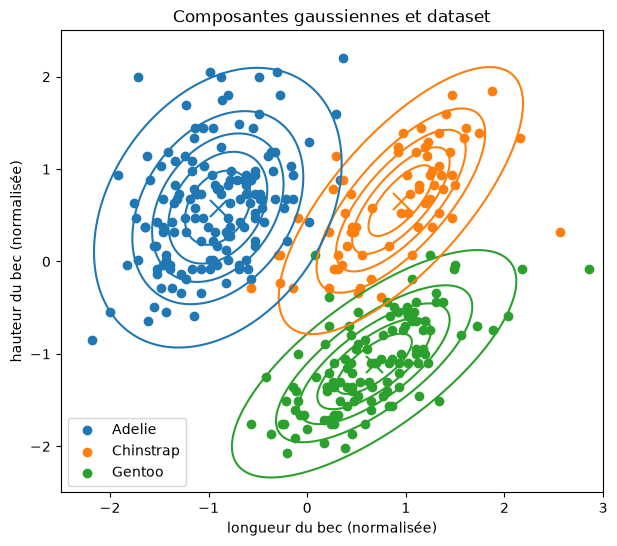

In [22]:
# on peut aussi comme précédemment affiche les 3 gaussiennes apprises

couleurs = {"Adelie": "C0", "Chinstrap": "C1", "Gentoo": "C2"}

plt.figure(figsize=(7, 6))
for e in couleurs:
    plt.scatter(X_peng[vraies == e, 0], X_peng[vraies == e, 1], label=e, color=couleurs[e])

xx, yy = np.meshgrid(np.linspace(-2.5, 3, 300), np.linspace(-2.5, 2.5, 300))
for k in range(K):
    couleur = couleurs[pred[clusters == k][0]] # couleur de l'espèce associée au cluster k
    z = ss.multivariate_normal(mean=mu_best[k], cov=cov_best[k]).pdf(np.dstack((xx, yy)))
    niveaux = np.linspace(0.05 * z.max(), z.max(), 6) # cf Q4
    plt.contour(xx, yy, z, levels=niveaux, colors=couleur)
    plt.scatter(mu_best[k, 0], mu_best[k, 1], marker="x", s=150, color=couleur)

plt.title("Composantes gaussiennes et dataset")
plt.xlabel("longueur du bec (normalisée)")
plt.ylabel("hauteur du bec (normalisée)")
plt.legend()
plt.show()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Conclusion : on arrive bien à identifier la présence des 3 espèces, et à créer des clusters auxquels on peut assigner une observation, tout cela grâce à l'algorithme EM.
Ce qu'on a fait est aussi assez proche de ce qu'on ferait en Machine Learning pour de la classification (toutefois ici on n'a pas utilisé l'étiquette, puisqu'on a nous-même identifié 3 catégories différentes.).
</div>